# Figure 1 - Folded versus disordered energy landscapes (schematic)

Lotthammer, J. M. & Holehouse, A. S. *Disentangling folding from energetic traps in simulations of disordered proteins.* **J. Chem. Inf. Model.** (2025). doi:[10.1021/acs.jcim.4c02005](https://doi.org/10.1021/acs.jcim.4c02005)

**What the figure shows.** Two cartoon two-dimensional energy landscapes: (A) a folded protein with a single dominant minimum, and (B) a disordered protein with many shallow, comparable minima. Blue is low energy, red is high energy; axes and units are arbitrary. This is a conceptual figure - there is no simulation data behind it.

**How it is made.** Each landscape is a flat surface plus a sum of randomly placed two-dimensional Gaussian bumps (`penguin_helpers.gaussian_noise`, adapted from Max Zimmerman's `slandscapes`). The folded landscape uses one deep, broad well plus thirty small bumps; the disordered landscape uses a 4x4 grid of moderate wells plus a 15x15 grid of bumps of either sign.

**Reproducibility note.** The published figure was generated with the legacy `np.random.seed(123)` global RNG. The helper now takes an explicit `numpy.random.Generator`, so the exact bump placement differs from the printed figure while the construction and appearance are the same. The insets (example conformations) were added in a vector graphics editor and are not reproduced here.

## Setup

All notebooks in this directory share `penguin_helpers.py`, a thin layer over SOURSOP's public `soursop.sssampling.SamplingQuality` API that handles data discovery, the manuscript's matplotlib style, and the four-panel PENGUIN figure. The trajectories (~6 GB) live in `data/`, one folder per system with `full/` and `ev/` replicates (see `data/README.md`); they are too large for the SOURSOP repository, so set `PENGUIN_DATA_DIR` if you keep them elsewhere.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms

from penguin_helpers import set_manuscript_style, figure_path, gaussian_noise

set_manuscript_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

## Build the two landscapes

In [2]:
rng = np.random.default_rng(123)

x = np.linspace(0, 100, 500)
y = np.linspace(0, 100, 500)
X, Y = np.meshgrid(x, y)

# folded: one deep well and a sprinkling of small roughness
Z_folded = np.full(X.shape, 15.0)
Z_folded += gaussian_noise(X, Y, gaussians_per_axis=1, height_range=(-13, -12), width_range=(6, 11), rng=rng)
Z_folded += gaussian_noise(X, Y, gaussians_per_axis=30, height_range=(-2, 0.25), width_range=(4, 5), rng=rng)

# disordered: many wells of similar depth
Z_disordered = np.full(X.shape, 10.0)
Z_disordered += gaussian_noise(X, Y, gaussians_per_axis=4, height_range=(-6, -5), width_range=(5, 9), rng=rng)
Z_disordered += gaussian_noise(X, Y, gaussians_per_axis=15, height_range=(-5, 3), width_range=(4, 5), rng=rng)

## Plot

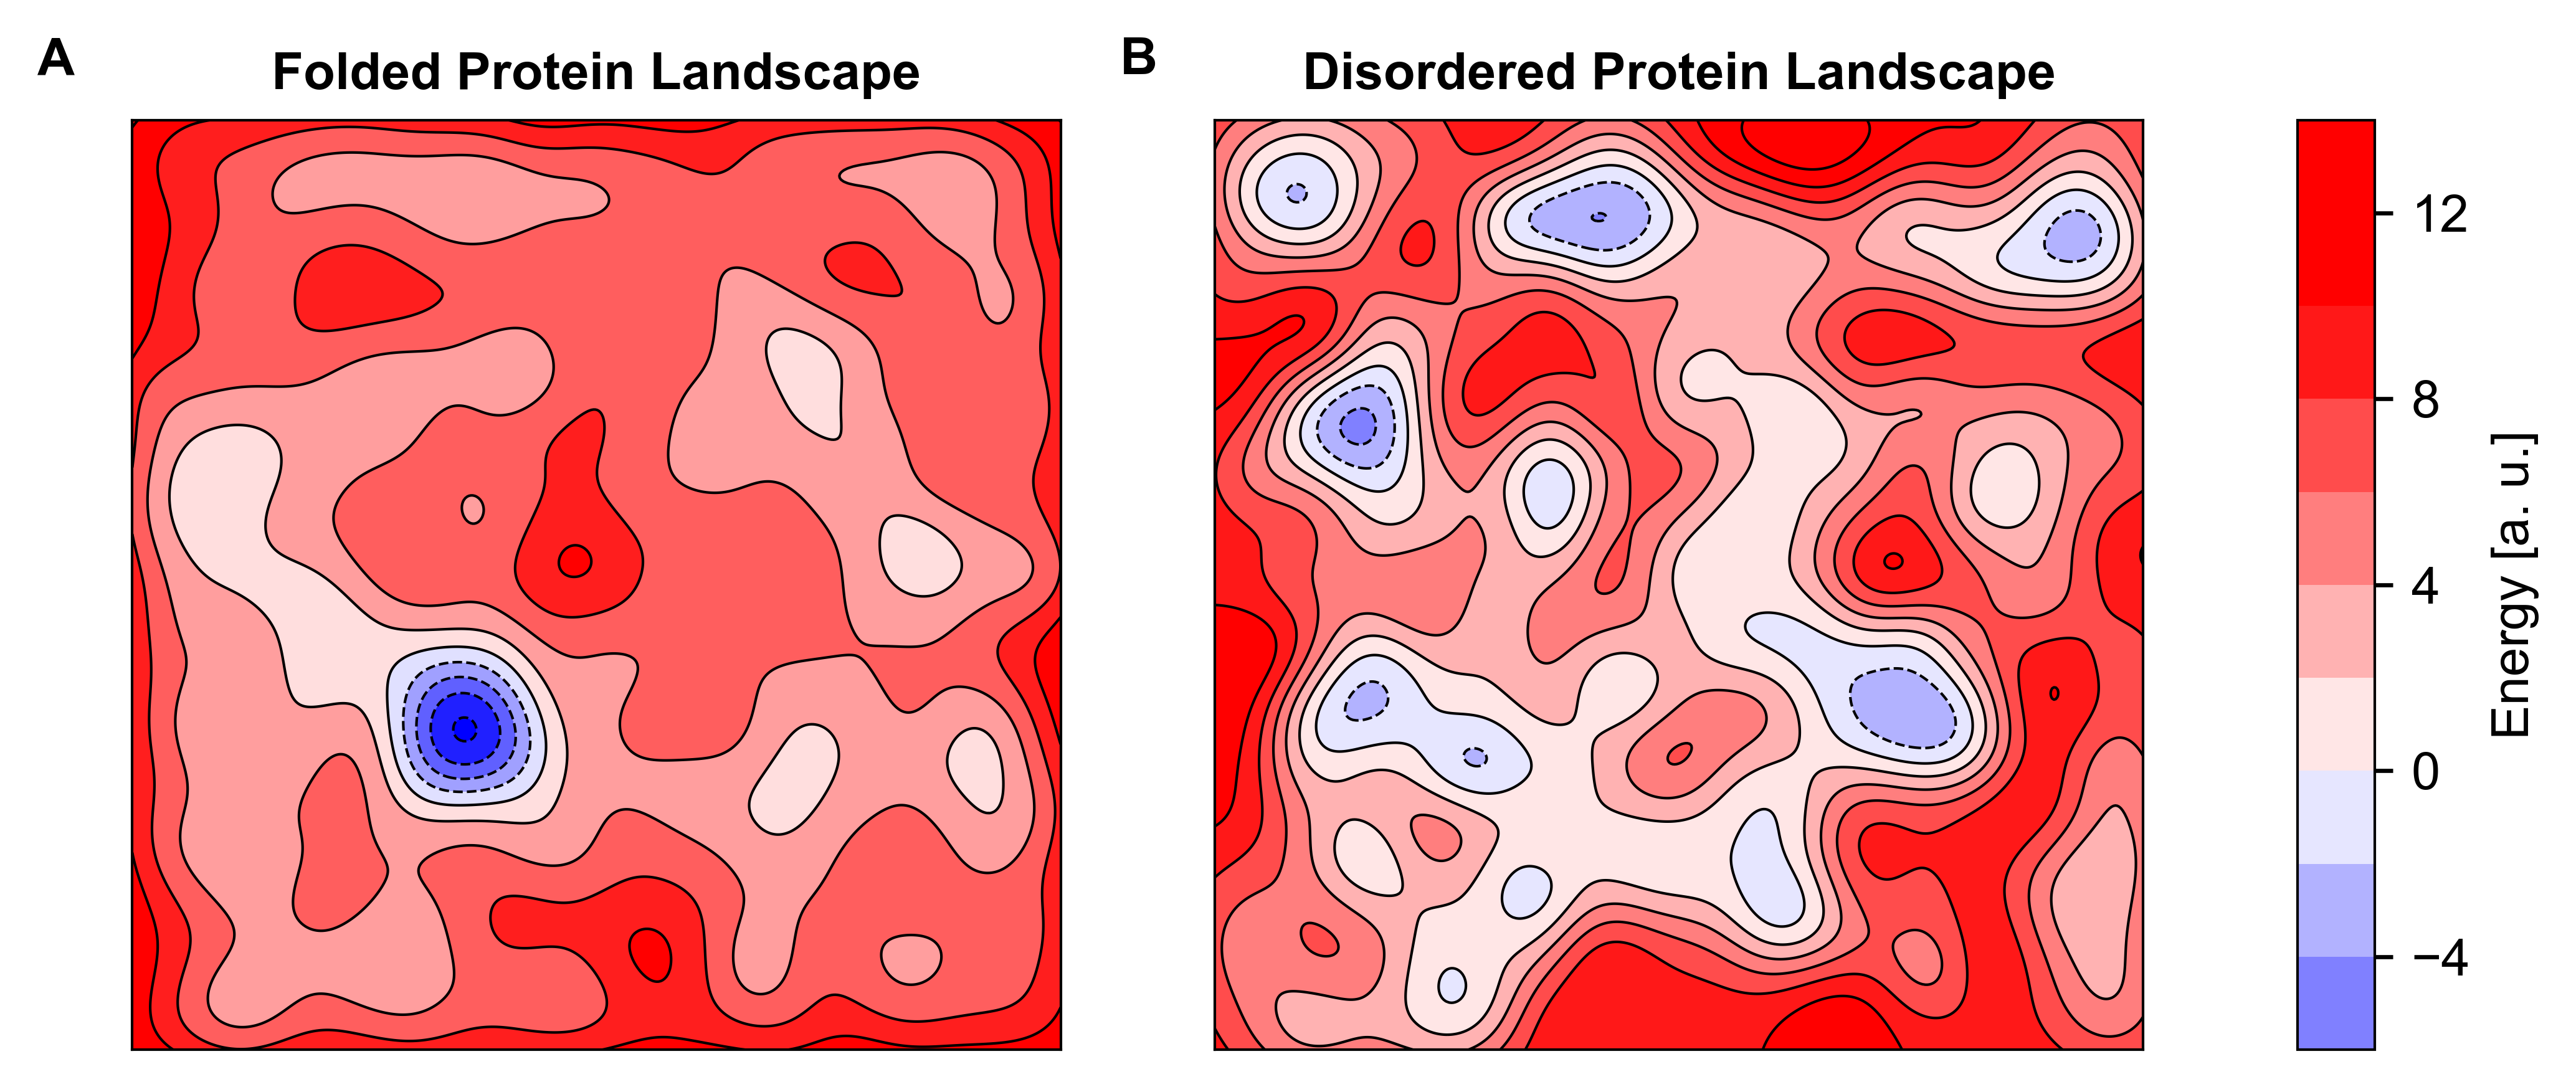

In [3]:
cmap = "bwr"
fig, axd = plt.subplot_mosaic("ABC", figsize=(7, 3), facecolor="w", dpi=300,
                              gridspec_kw={"width_ratios": [3, 3, 0.25]})

for label, Z, title in [("A", Z_folded, "Folded Protein Landscape"),
                        ("B", Z_disordered, "Disordered Protein Landscape")]:
    ax = axd[label]
    ax.set_title(title, fontsize=10, fontweight="bold")
    cf = ax.contourf(X, Y, Z, 10, zorder=0, cmap=cmap, vmin=-10, vmax=10)
    ax.contour(X, Y, Z, 10, colors="black", linewidths=0.5)
    ax.set_xticks([]); ax.set_yticks([])
    trans = mtransforms.ScaledTranslation(-20 / 72, 7 / 72, fig.dpi_scale_trans)
    ax.text(0.05, 1.05, label, transform=ax.transAxes + trans,
            fontsize=10, fontweight="bold", va="top", ha="right")

fig.colorbar(cf, cax=axd["C"], label="Energy [a. u.]")
fig.tight_layout()
fig.savefig(figure_path("fig1", "landscape_comparison.pdf"), dpi=300)